# ARTI 502 – Deep Learning: 1st Assignment
Training-Testing Neural Net with MNIST Dataset using PyTorch

## Task #1: Install PyTorch

In [1]:
%pip install --disable-pip-version-check torch==2.14.0 torchvision==0.29.0 --index-url https://download.pytorch.org/whl/cu126
%pip install --disable-pip-version-check matplotlib

Defaulting to user installation because normal site-packages is not writeable
Looking in indexes: https://download.pytorch.org/whl/cu126
Note: you may need to restart the kernel to use updated packages.
Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [2]:
import math
import os
import time

import matplotlib.colors as colors
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
from torch.utils.data import DataLoader, random_split


print(f"PyTorch {torch.__version__}")
print(f"torchvision {torchvision.__version__}")

device = torch.device("cuda")
print(f"CUDA available: {torch.cuda.is_available()}")
print(f"device in use: {device}")
print(f"GPU: {torch.cuda.get_device_name(0)}")

SEED = 42
torch.manual_seed(SEED)


PyTorch 2.14.0+cu126
torchvision 0.29.0+cu126
CUDA available: True
device in use: cuda
GPU: NVIDIA GeForce GTX 1080 Ti


## Task #2: Download and Load the Dataset

In [3]:
MEAN, STD = 0.1307, 0.3081
transform = transforms.Compose([transforms.ToTensor(), transforms.Normalize((MEAN,), (STD,))])

train_full = torchvision.datasets.MNIST(root="dataset", train=True, download=True, transform=transform)
test_set = torchvision.datasets.MNIST(root="dataset", train=False, download=True, transform=transform)
train_set, val_set = random_split(train_full, [50000, 10000], generator=torch.Generator().manual_seed(SEED))

train_loader = DataLoader(train_set, batch_size=32, shuffle=True)
val_loader = DataLoader(val_set, batch_size=1000)
test_loader = DataLoader(test_set, batch_size=1000)

for file in sorted(os.listdir(train_full.raw_folder)):
    path = os.path.join(train_full.raw_folder, file)

print(f"Files downloaded to {train_full.raw_folder}.")

Files downloaded to dataset\MNIST\raw.


Downloaded the MNIST files into `dataset/MNIST/raw` and loaded them: 
- 50,000 training images
- 10,000 test images
- 10,000 for validation

## Task #3: Inspect the Dataset

Images tensor size: torch.Size([32, 1, 28, 28])
Labels tensor size: torch.Size([32])
Raw training images tensor size: torch.Size([60000, 28, 28])


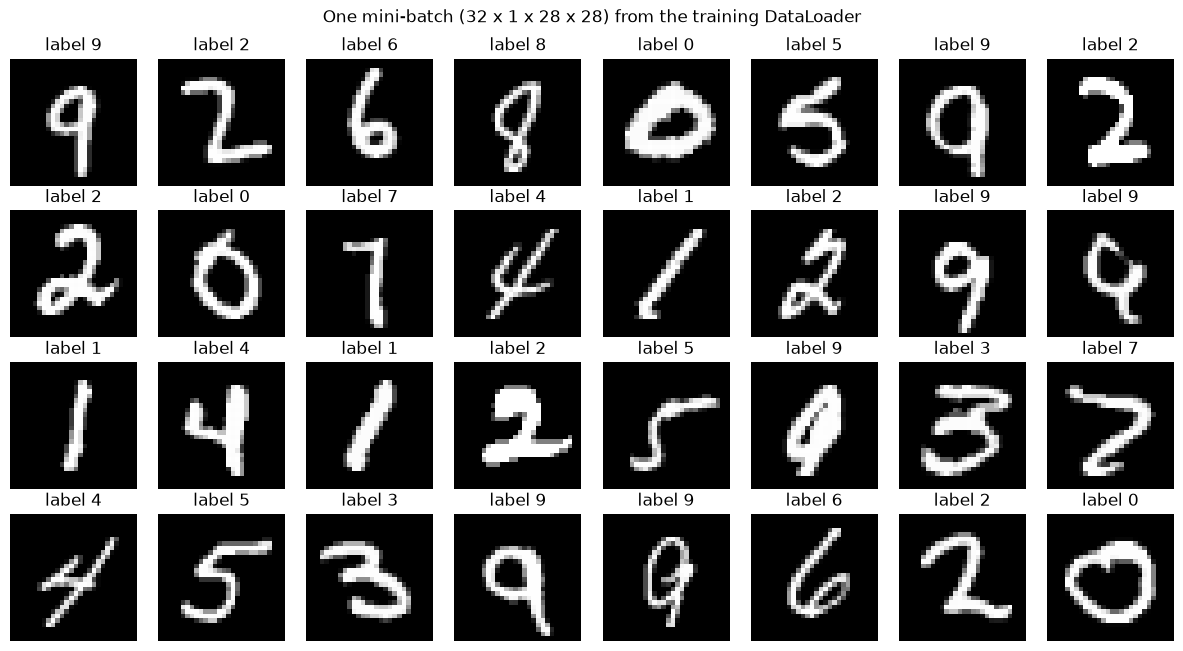

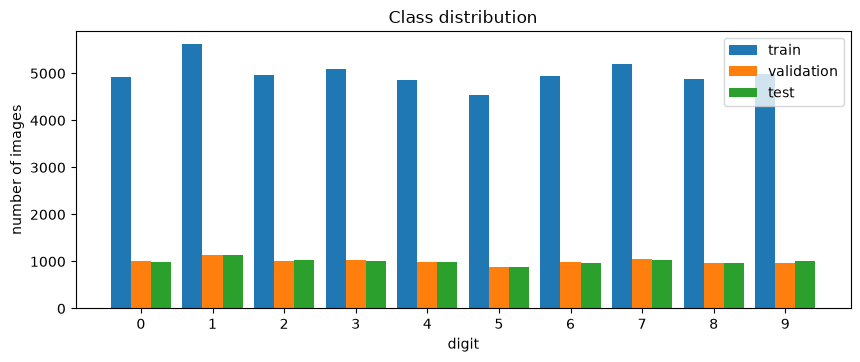

In [4]:
images, labels = next(iter(train_loader))
print("Images tensor size:", images.size())
print("Labels tensor size:", labels.size())
print("Raw training images tensor size:", train_full.data.size())

fig, axes = plt.subplots(4, 8, figsize=(12, 6.6))
for i in range(32):
    ax = axes.flat[i]
    ax.imshow(images[i].squeeze() * STD + MEAN, cmap="gray")
    ax.set_title(f"label {labels[i].item()}")
    ax.axis("off")
fig.suptitle("One mini-batch (32 x 1 x 28 x 28) from the training DataLoader")
plt.tight_layout()
plt.show()

train_counts = torch.bincount(train_full.targets[train_set.indices], minlength=10)
val_counts = torch.bincount(train_full.targets[val_set.indices], minlength=10)
test_counts = torch.bincount(test_set.targets, minlength=10)
digits = torch.arange(10)
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.bar(digits - 0.28, train_counts, width=0.28, label="train")
ax.bar(digits, val_counts, width=0.28, label="validation")
ax.bar(digits + 0.28, test_counts, width=0.28, label="test")
ax.set(xticks=range(10), xlabel="digit", ylabel="number of images", title="Class distribution")
ax.legend()
plt.show()

The DataLoader returns:
- mini-batch tensor of size 32 × 1 × 28 × 28 (batch × channel × height × width) 
- the labels as a tensor of size 32.   
Each image is 1 × 28 × 28  


The bar chart shows that the ten digits
are roughly balanced in the training, validation and test sets.

## Task #4: Creating A Simple Network

In [5]:
class SimpleNet(nn.Module):
    def __init__(self, inputs=784, hidden=512, outputs=10):
        super().__init__()
        self.fc1 = nn.Linear(inputs, hidden)
        self.fc2 = nn.Linear(hidden, outputs)

    def forward(self, x):
        x = torch.flatten(x, 1)
        x = F.relu(self.fc1(x))
        return self.fc2(x)


net = SimpleNet().to(device)
print(net)
print("Trainable parameters:", sum(p.numel() for p in net.parameters()))
x = images.to(device)
print("Input batch:", tuple(x.shape))
print("-> flattened:", tuple(torch.flatten(x, 1).shape))
print("-> output:", tuple(net(x).shape))

SimpleNet(
  (fc1): Linear(in_features=784, out_features=512, bias=True)
  (fc2): Linear(in_features=512, out_features=10, bias=True)
)
Trainable parameters: 407050
Input batch: (32, 1, 28, 28)
-> flattened: (32, 784)
-> output: (32, 10)


`SimpleNet`:
- `torch.flatten` rearranges a batch from 32 × 1 × 28 × 28 -->  32 × 784
- a hidden layer (fully connected layer): maps the 784 inputs to 512 hidden neurons
- ReLU activation 
- An output layer that maps to  10 outputs
- 407,050 trainable parameters. 

## Task #5: Training Function

In [6]:
def evaluate(net, dataloader):
    criterion = nn.CrossEntropyLoss(reduction="sum")
    net.eval()
    total_loss = 0.0
    correct = 0
    count = 0
    with torch.no_grad():
        for inputs, labels in dataloader:
            inputs = inputs.to(device)
            labels = labels.to(device)
            outputs = net(inputs)
            total_loss += criterion(outputs, labels).item()
            correct += (outputs.argmax(1) == labels).sum().item()
            count += labels.size(0)
    return total_loss / count, correct / count


def train(net, dataloader, epochs=1, lr=0.01, momentum=0.9, weight_decay=0.0, nesterov=False, cosine=False,
          val_loader=None, val_name="val", verbose=True):
    net.to(device)
    criterion = nn.CrossEntropyLoss()
    optimizer = optim.SGD(net.parameters(), lr=lr, momentum=momentum, weight_decay=weight_decay, nesterov=nesterov, fused=True)
    total_steps = epochs * len(dataloader)
    warmup_steps = int(0.03 * total_steps)

    # optional learning-rate schedule: 3% linear warm-up, then cosine decay to zero
    def lr_factor(step):
        if not cosine:
            return 1.0
        if step < warmup_steps:
            return (step + 1) / warmup_steps
        return 0.5 * (1 + math.cos(math.pi * (step - warmup_steps) / (total_steps - warmup_steps)))

    scheduler = optim.lr_scheduler.LambdaLR(optimizer, lr_factor)
    losses = []
    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    for epoch in range(1, epochs + 1):
        net.train()
        loss_sum = torch.zeros((), device=device)
        correct = torch.zeros((), device=device)
        seen = 0
        for inputs, labels in dataloader:
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = net(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()
            scheduler.step()
            
            losses.append(loss.item())
            loss_sum += loss.detach() * labels.size(0)
            correct += (outputs.argmax(1) == labels).sum()
            seen += labels.size(0)
            
            
        history["train_loss"].append(loss_sum.item() / seen)
        history["train_acc"].append(correct.item() / seen)
        message = (f"epoch {epoch:3d}/{epochs} | train loss {history['train_loss'][-1]:.4f} | "
                   f"train accuracy {100 * history['train_acc'][-1]:.2f}%")
        if val_loader is not None:
            val_loss, val_acc = evaluate(net, val_loader)
            history["val_loss"].append(val_loss)
            history["val_acc"].append(val_acc)
            message += f" | {val_name} loss {val_loss:.4f} | {val_name} accuracy {100 * val_acc:.2f}%"

        if verbose:
            print(message)
    return losses, history

`train()` takes:
- the network
- training DataLoader
- optional parameters (epochs, learning rate, momentum, …)

It uses:
- `nn.CrossEntropyLoss`
- stochastic gradient descent (`optim.SGD`) with a learning rate and momentum

Prints the epoch, loss, and accuracy

Returns:
- the list of all mini-batch losses
- the loss and accuracy of every epoch.   
  
    
`evaluate()` returns the average loss and the accuracy of a network on a dataset.

## Task #6: Training Network

In [7]:
torch.manual_seed(SEED)
net = SimpleNet().to(device)
start = time.time()
losses, history = train(net, train_loader, epochs=10, lr=0.01, momentum=0.9, val_loader=val_loader)
print(f"Training time: {time.time() - start:.1f} s | recorded mini-batch losses: {len(losses)}")

epoch   1/10 | train loss 0.2213 | train accuracy 93.36% | val loss 0.1322 | val accuracy 96.09%
epoch   2/10 | train loss 0.0835 | train accuracy 97.45% | val loss 0.0991 | val accuracy 97.10%
epoch   3/10 | train loss 0.0511 | train accuracy 98.40% | val loss 0.0801 | val accuracy 97.58%
epoch   4/10 | train loss 0.0321 | train accuracy 99.08% | val loss 0.0880 | val accuracy 97.30%
epoch   5/10 | train loss 0.0230 | train accuracy 99.34% | val loss 0.0767 | val accuracy 97.82%
epoch   6/10 | train loss 0.0143 | train accuracy 99.67% | val loss 0.0796 | val accuracy 97.62%
epoch   7/10 | train loss 0.0089 | train accuracy 99.82% | val loss 0.0731 | val accuracy 97.78%
epoch   8/10 | train loss 0.0056 | train accuracy 99.92% | val loss 0.0782 | val accuracy 97.76%
epoch   9/10 | train loss 0.0037 | train accuracy 99.97% | val loss 0.0727 | val accuracy 97.89%
epoch  10/10 | train loss 0.0024 | train accuracy 99.99% | val loss 0.0734 | val accuracy 97.86%
Training time: 145.2 s | recor

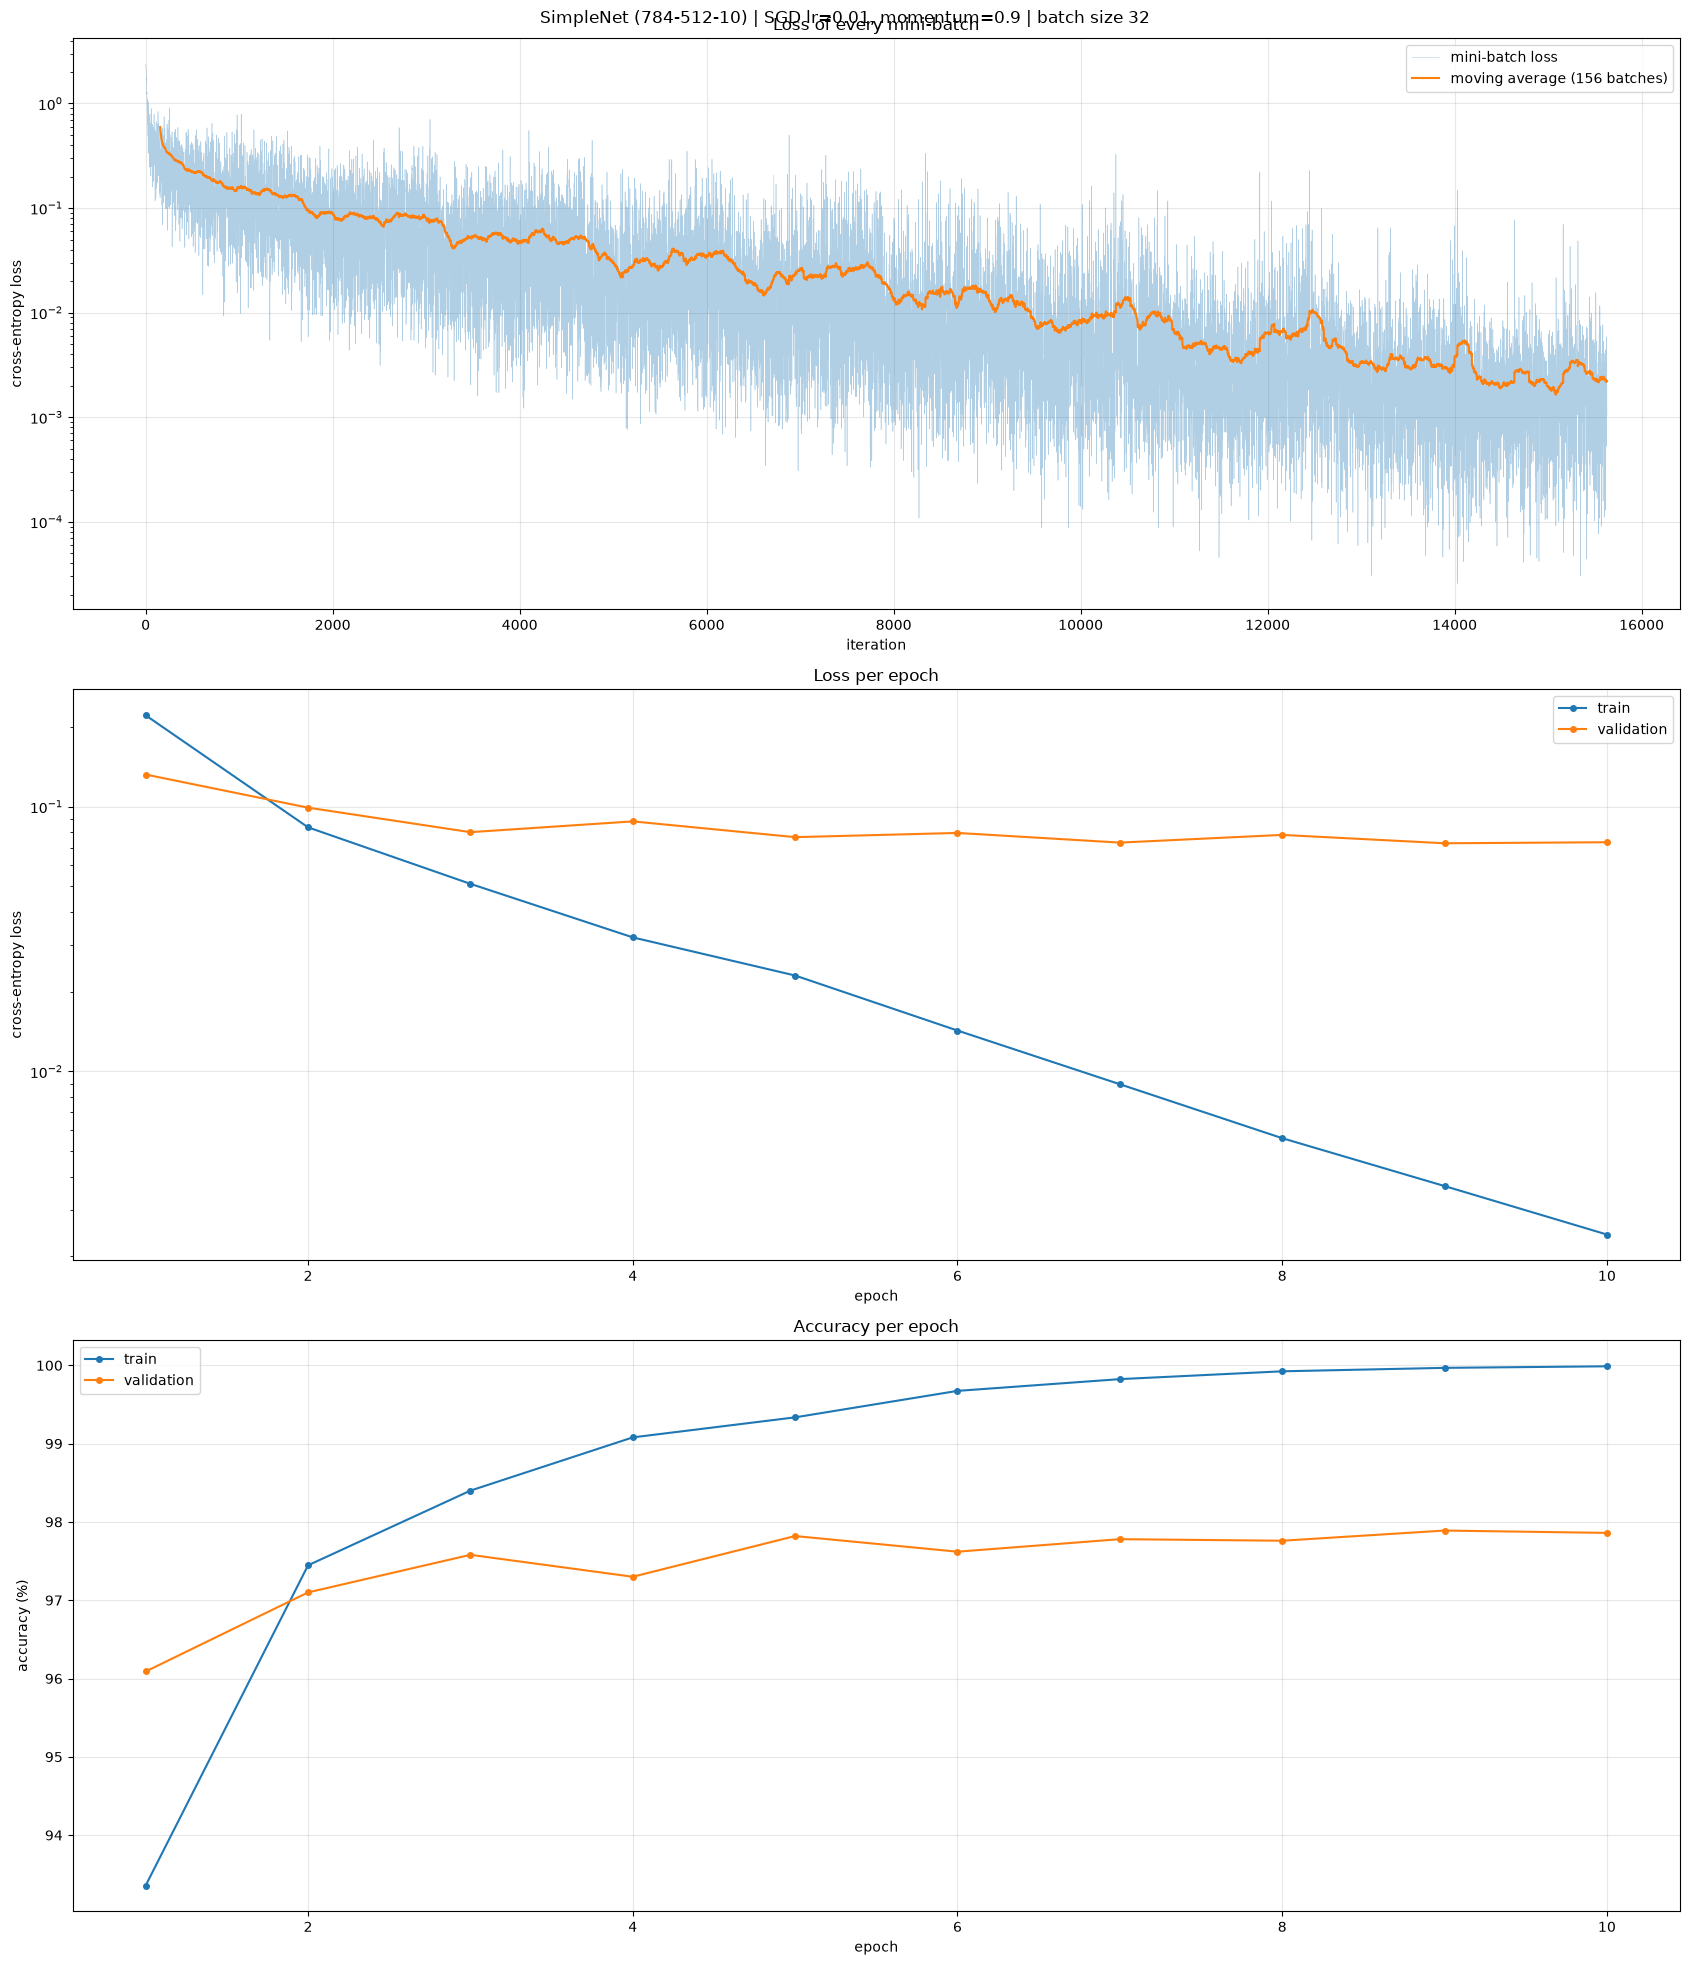

In [8]:
def plot_training(losses, history, title, val_name="validation"):
    # moving average over 1% of all mini-batches
    window = len(losses) // 100
    moving_average = []
    total = 0.0
    for i in range(len(losses)):
        total += losses[i]
        if i >= window:
            total -= losses[i - window]
        if i >= window - 1:
            moving_average.append(total / window)

    epochs = range(1, len(history["train_loss"]) + 1)
    marker = None
    if len(epochs) <= 30:
        marker = "o"
    train_acc = [100 * a for a in history["train_acc"]]
    val_acc = [100 * a for a in history["val_acc"]]

    fig, axes = plt.subplots(3, 1, figsize=(17, 20))
    axes[0].plot(losses, lw=0.4, alpha=0.35, label="mini-batch loss")
    axes[0].plot(range(window - 1, len(losses)), moving_average, lw=1.5, label=f"moving average ({window} batches)")
    axes[0].set(title="Loss of every mini-batch", xlabel="iteration", ylabel="cross-entropy loss", yscale="log")
    axes[1].plot(epochs, history["train_loss"], marker=marker, ms=4, label="train")
    axes[1].plot(epochs, history["val_loss"], marker=marker, ms=4, label=val_name)
    axes[1].set(title="Loss per epoch", xlabel="epoch", ylabel="cross-entropy loss", yscale="log")
    axes[2].plot(epochs, train_acc, marker=marker, ms=4, label="train")
    axes[2].plot(epochs, val_acc, marker=marker, ms=4, label=val_name)
    axes[2].set(title="Accuracy per epoch", xlabel="epoch", ylabel="accuracy (%)")
    for ax in axes:
        ax.grid(alpha=0.3)
        ax.legend()
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


plot_training(losses, history, "SimpleNet (784-512-10) | SGD lr=0.01, momentum=0.9 | batch size 32")

with:
- learning rate = 0.01
- momentum = 0.9
- batch size 32
the training accuracy reached 99.99%. The validation accuracy rose from 96.09% to 97.86%.  

The validation loss stopped improving after about epoch 5 while the training loss kept falling: 
- the simple network starts to overfit the training images.

## Task #7: Testing Network

SimpleNet on all 10000 test images -> loss 0.0600 | accuracy 98.35%
Predicted: [3, 5, 1, 9, 4, 9, 3, 1, 1, 4, 3, 9, 0, 6, 4, 9, 6, 9, 3, 4, 1, 3, 2, 8]
Actual:    [3, 5, 1, 9, 4, 9, 3, 1, 1, 4, 3, 9, 0, 6, 4, 9, 6, 9, 3, 4, 1, 3, 2, 8]


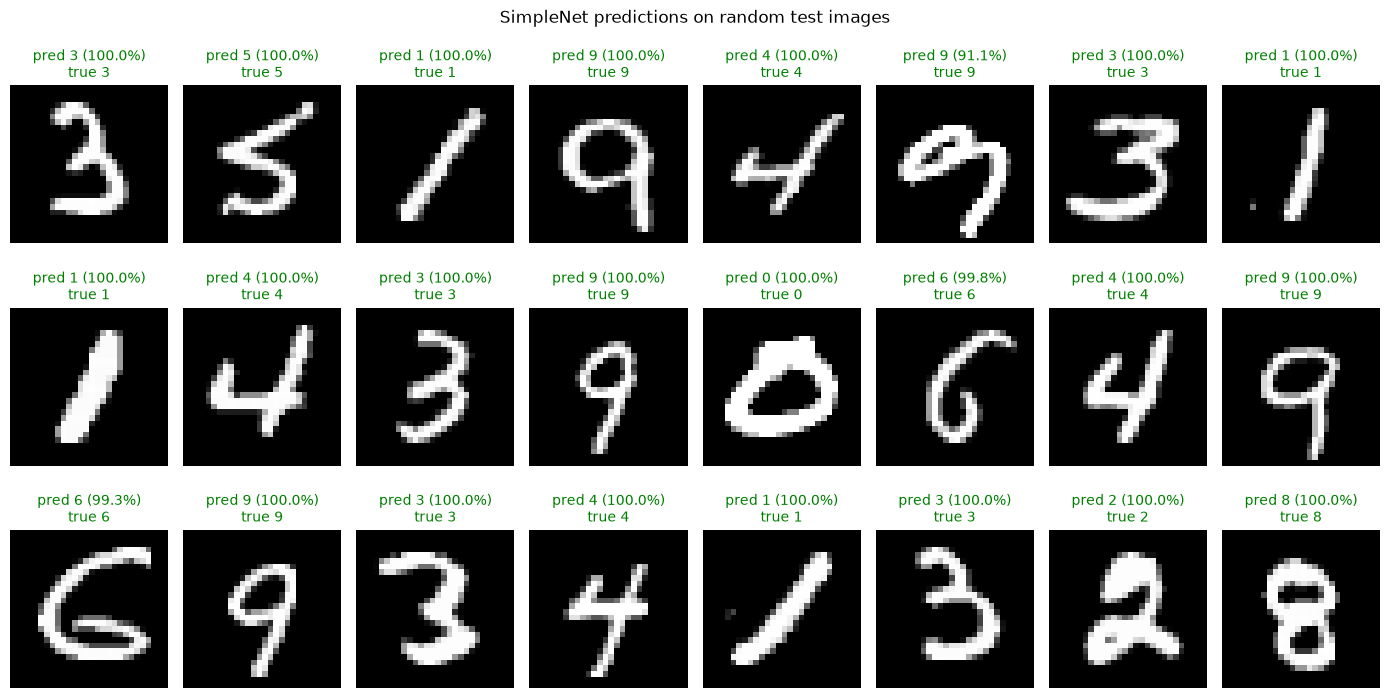

In [9]:
test_loss, test_acc = evaluate(net, test_loader)
print(f"SimpleNet on all {len(test_set)} test images -> loss {test_loss:.4f} | accuracy {100 * test_acc:.2f}%")

sample_images, sample_labels = next(iter(DataLoader(test_set, batch_size=24, shuffle=True, generator=torch.Generator().manual_seed(SEED))))
net.eval()
with torch.no_grad():
    probabilities = F.softmax(net(sample_images.to(device)), dim=1).cpu()
confidence, predicted = probabilities.max(1)
print("Predicted:", predicted.tolist())
print("Actual:   ", sample_labels.tolist())

fig, axes = plt.subplots(3, 8, figsize=(14, 7.4))
for i in range(24):
    ax = axes.flat[i]
    color = "green"
    if predicted[i] != sample_labels[i]:
        color = "red"
    ax.imshow(sample_images[i].squeeze() * STD + MEAN, cmap="gray")
    ax.set_title(f"pred {predicted[i].item()} ({100 * confidence[i]:.1f}%)\ntrue {sample_labels[i].item()}", color=color, fontsize=10)
    ax.axis("off")
fig.suptitle("SimpleNet predictions on random test images")
plt.tight_layout()
plt.show()

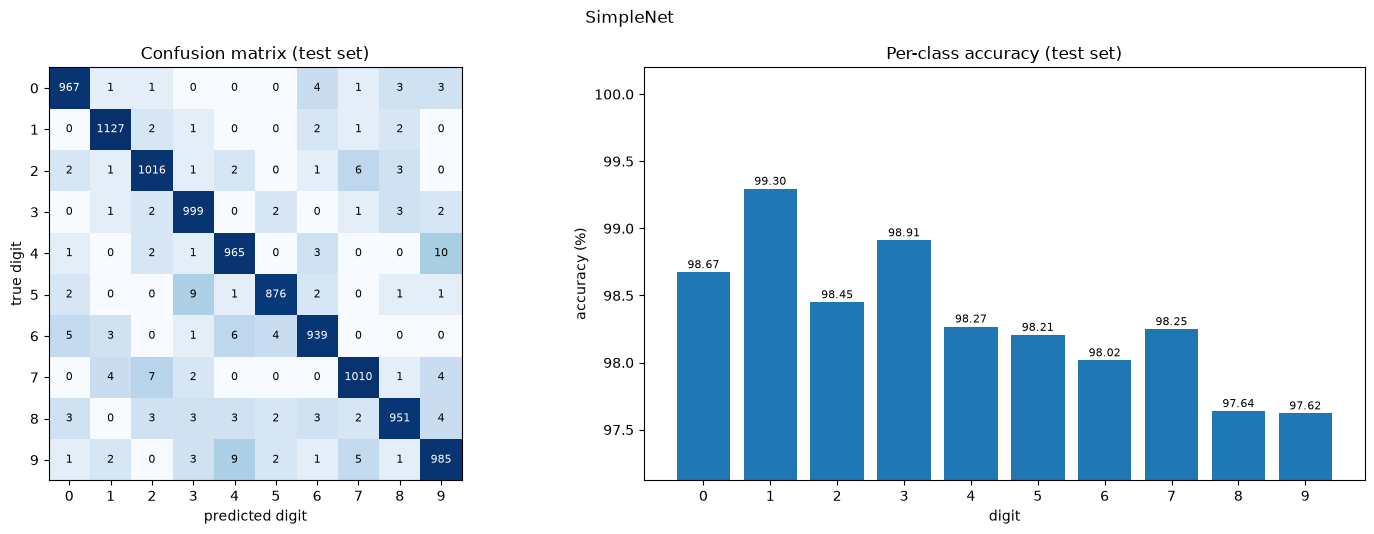

Misclassified test images: 165 of 10000


In [10]:
def plot_confusion(net, dataloader, title):
    predictions = []
    targets = []
    net.eval()
    with torch.no_grad():
        for inputs, labels in dataloader:
            predictions += net(inputs.to(device)).argmax(1).tolist()
            targets += labels.tolist()
    confusion = torch.zeros(10, 10, dtype=torch.long)
    for t, p in zip(targets, predictions):
        confusion[t, p] += 1
    per_class = 100 * confusion.diag() / confusion.sum(1)

    fig, axes = plt.subplots(1, 2, figsize=(15, 5.4))
    axes[0].imshow(torch.log(confusion.float() + 1), cmap="Blues")
    for i in range(10):
        for j in range(10):
            color = "black"
            if i == j:
                color = "white"
            axes[0].text(j, i, confusion[i, j].item(), ha="center", va="center", fontsize=8, color=color)
    axes[0].set(xticks=range(10), yticks=range(10), xlabel="predicted digit", ylabel="true digit", title="Confusion matrix (test set)")
    axes[1].bar(range(10), per_class, color="tab:blue")
    for i in range(10):
        axes[1].text(i, per_class[i].item() + 0.03, f"{per_class[i]:.2f}", ha="center", fontsize=8)
    axes[1].set(xticks=range(10), ylim=(per_class.min().item() - 0.5, 100.2), xlabel="digit", ylabel="accuracy (%)", title="Per-class accuracy (test set)")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

    misclassified = []
    for i in range(len(targets)):
        if predictions[i] != targets[i]:
            misclassified.append(i)
    return misclassified, predictions


misclassified, _ = plot_confusion(net, test_loader, "SimpleNet")
print(f"Misclassified test images: {len(misclassified)} of {len(test_set)}")

The errors are mostly between digits that look alike: 
- 4 predicted as 9 (10 images)
- 9 as 4 (9)
- 5 as 3 (9) 
- 7 as 2 (7). 

Digit 1 is recognized best (99.30%) 
Digits 8 and 9 are the hardest (97.64% and 97.62%)

## Task #8: Tuning the parameters and model architecture

GPU tensors -> train: (50000, 1, 28, 28) | validation: (10000, 1, 28, 28) | train + validation: (60000, 1, 28, 28) | test: (10000, 1, 28, 28)


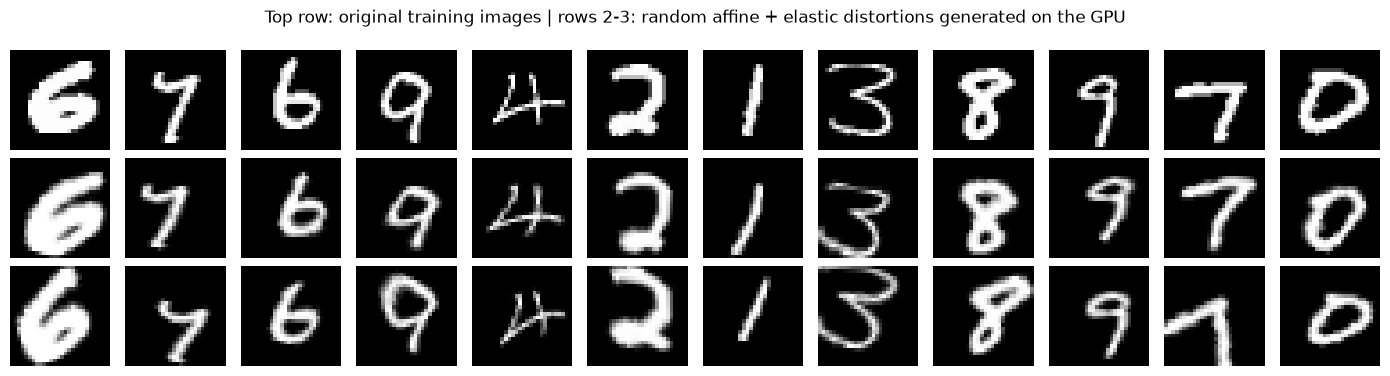

In [11]:
# whole dataset as GPU tensors (pixel values 0-1) for fast training
X_train = train_full.data[train_set.indices].unsqueeze(1).float().div(255).to(device)
Y_train = train_full.targets[train_set.indices].to(device)
X_val = train_full.data[val_set.indices].unsqueeze(1).float().div(255).to(device)
Y_val = train_full.targets[val_set.indices].to(device)
X_all = train_full.data.unsqueeze(1).float().div(255).to(device)
Y_all = train_full.targets.to(device)
X_test = test_set.data.unsqueeze(1).float().div(255).to(device)
Y_test = test_set.targets.to(device)


def augment(x, params):
    n = x.size(0)
    # random affine transform: rotation, shear, scaling and translation
    angle = (torch.rand(n, device=device) * 2 - 1) * math.radians(params["rotate"])
    shear = (torch.rand(n, device=device) * 2 - 1) * math.radians(params["shear"])
    sx = 1 + (torch.rand(n, device=device) * 2 - 1) * params["scale"]
    sy = 1 + (torch.rand(n, device=device) * 2 - 1) * params["scale"]
    tx = (torch.rand(n, device=device) * 2 - 1) * 2 * params["shift"]
    ty = (torch.rand(n, device=device) * 2 - 1) * 2 * params["shift"]
    cos, sin, tan = angle.cos(), angle.sin(), shear.tan()
    theta = torch.zeros(n, 2, 3, device=device)
    theta[:, 0, 0] = cos / sx
    theta[:, 0, 1] = (cos * tan - sin) / sy
    theta[:, 0, 2] = tx
    theta[:, 1, 0] = sin / sx
    theta[:, 1, 1] = (sin * tan + cos) / sy
    theta[:, 1, 2] = ty
    grid = F.affine_grid(theta, x.size(), align_corners=False)
    # elastic distortion: random displacement field smoothed with a Gaussian (sigma = 5 pixels)
    pos = torch.arange(28, dtype=torch.float32, device=device)
    gauss = torch.exp(-(pos.unsqueeze(1) - pos.unsqueeze(0)) ** 2 / (2 * 5.0 ** 2))
    gauss = gauss / gauss.sum(1, keepdim=True)
    field = gauss @ (torch.rand(n, 2, 28, 28, device=device) * 2 - 1) @ gauss.T
    grid = grid + field.permute(0, 2, 3, 1) * (2 * params["elastic"] / 28)
    return F.grid_sample(x, grid, padding_mode="zeros", align_corners=False)


class GPULoader:
    def __init__(self, images, labels, batch_size, shuffle=False, augmentation=None):
        self.images = images
        self.labels = labels
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.augmentation = augmentation

    def __len__(self):
        return math.ceil(len(self.images) / self.batch_size)

    def __iter__(self):
        images = self.images
        labels = self.labels
        if self.shuffle:
            order = torch.randperm(len(images), device=device)
            images = images[order]
            labels = labels[order]
        if self.augmentation is not None:
            chunks = []
            for chunk in images.split(10000):
                chunks.append(augment(chunk, self.augmentation))
            images = torch.cat(chunks)
        images = (images - MEAN) / STD
        for start in range(0, len(images), self.batch_size):
            yield images[start:start + self.batch_size], labels[start:start + self.batch_size]


class MLP(nn.Module):
    def __init__(self, hidden, dropout=0.0):
        super().__init__()
        layers = []
        size = 784
        for units in hidden:
            layers.append(nn.Linear(size, units))
            layers.append(nn.ReLU())
            layers.append(nn.Dropout(dropout))
            size = units
        layers.append(nn.Linear(size, 10))
        self.layers = nn.Sequential(*layers)
        for layer in self.layers:
            if isinstance(layer, nn.Linear):
                nn.init.kaiming_normal_(layer.weight, nonlinearity="relu")
                nn.init.zeros_(layer.bias)

    def forward(self, x):
        return self.layers(torch.flatten(x, 1))


val_gpu = GPULoader(X_val, Y_val, 10000)
test_gpu = GPULoader(X_test, Y_test, 10000)
print("GPU tensors -> train:", tuple(X_train.shape), "| validation:", tuple(X_val.shape), "| train + validation:", tuple(X_all.shape), "| test:", tuple(X_test.shape))

torch.manual_seed(SEED)
originals = X_train[:12]
augmented = augment(torch.cat([originals, originals]), {"rotate": 12, "scale": 0.12, "shear": 12, "shift": 0.1, "elastic": 30})
examples = torch.cat([originals, augmented]).cpu()
fig, axes = plt.subplots(3, 12, figsize=(14, 3.8))
for i in range(36):
    axes.flat[i].imshow(examples[i].squeeze(), cmap="gray")
    axes.flat[i].axis("off")
fig.suptitle("Top row: original training images | rows 2-3: random affine + elastic distortions generated on the GPU")
plt.tight_layout()
plt.show()

In [12]:
def plot_grid(grid, rows, cols, row_label, col_label, title):
    fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))
    for k in range(2):
        # left: accuracy (%), right: loss; runs that diverged (accuracy <= 20%) are left blank
        values = torch.zeros(len(rows), len(cols))
        for i in range(len(rows)):
            for j in range(len(cols)):
                loss, acc = grid[(rows[i], cols[j])]
                if acc <= 0.2:
                    values[i, j] = float("nan")
                elif k == 0:
                    values[i, j] = 100 * acc
                else:
                    values[i, j] = loss
        shown = values[~values.isnan()]
        if k == 0:
            best = shown.max().item()
            norm = colors.Normalize(max(shown.min().item(), best - 5), best)
            image = axes[k].imshow(values, cmap="viridis", norm=norm, aspect="auto")
        else:
            norm = colors.LogNorm(shown.min().item(), shown.max().item())
            image = axes[k].imshow(values, cmap="viridis_r", norm=norm, aspect="auto")
        for i in range(len(rows)):
            for j in range(len(cols)):
                v = values[i, j].item()
                if math.isnan(v):
                    axes[k].text(j, i, "diverged", ha="center", va="center", fontsize=9)
                    continue
                r, g, b, _ = image.cmap(image.norm(v))
                color = "white"
                if 0.299 * r + 0.587 * g + 0.114 * b > 0.5:
                    color = "black"
                text = f"{v:.4f}"
                if k == 0:
                    text = f"{v:.2f}"
                axes[k].text(j, i, text, ha="center", va="center", fontsize=9, color=color)
        axes[k].set(xticks=range(len(cols)), xticklabels=cols, yticks=range(len(rows)), yticklabels=rows, xlabel=col_label, ylabel=row_label)
        fig.colorbar(image, ax=axes[k])
    axes[0].set_title("validation accuracy (%)")
    axes[1].set_title("validation loss")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


def report_best(grid, names):
    best_acc_key = None
    best_loss_key = None
    for key in grid:
        loss, acc = grid[key]
        if best_acc_key is None or acc > grid[best_acc_key][1]:
            best_acc_key = key
        if best_loss_key is None or loss < grid[best_loss_key][0]:
            best_loss_key = key
    loss, acc = grid[best_acc_key]
    print(f"Highest validation accuracy: {100 * acc:.2f}% (loss {loss:.4f}) with {names[0]} = {best_acc_key[0]}, {names[1]} = {best_acc_key[1]}")
    loss, acc = grid[best_loss_key]
    print(f"Lowest validation loss:      {loss:.4f} (accuracy {100 * acc:.2f}%) with {names[0]} = {best_loss_key[0]}, {names[1]} = {best_loss_key[1]}")
    return best_acc_key

### 8.1 Learning rate and momentum

momentum 0.0   | lr 0.001  -> validation loss 0.2849 | validation accuracy 91.74%
momentum 0.0   | lr 0.003  -> validation loss 0.1873 | validation accuracy 94.59%
momentum 0.0   | lr 0.01   -> validation loss 0.1046 | validation accuracy 96.80%
momentum 0.0   | lr 0.03   -> validation loss 0.0747 | validation accuracy 97.66%
momentum 0.0   | lr 0.1    -> validation loss 0.0712 | validation accuracy 97.94%
momentum 0.0   | lr 0.3    -> validation loss 0.1341 | validation accuracy 97.59%
momentum 0.5   | lr 0.001  -> validation loss 0.2240 | validation accuracy 93.62%
momentum 0.5   | lr 0.003  -> validation loss 0.1333 | validation accuracy 96.04%
momentum 0.5   | lr 0.01   -> validation loss 0.0817 | validation accuracy 97.49%
momentum 0.5   | lr 0.03   -> validation loss 0.0703 | validation accuracy 97.87%
momentum 0.5   | lr 0.1    -> validation loss 0.0820 | validation accuracy 98.05%
momentum 0.5   | lr 0.3    -> validation loss 0.4346 | validation accuracy 95.26%
momentum 0.9   |

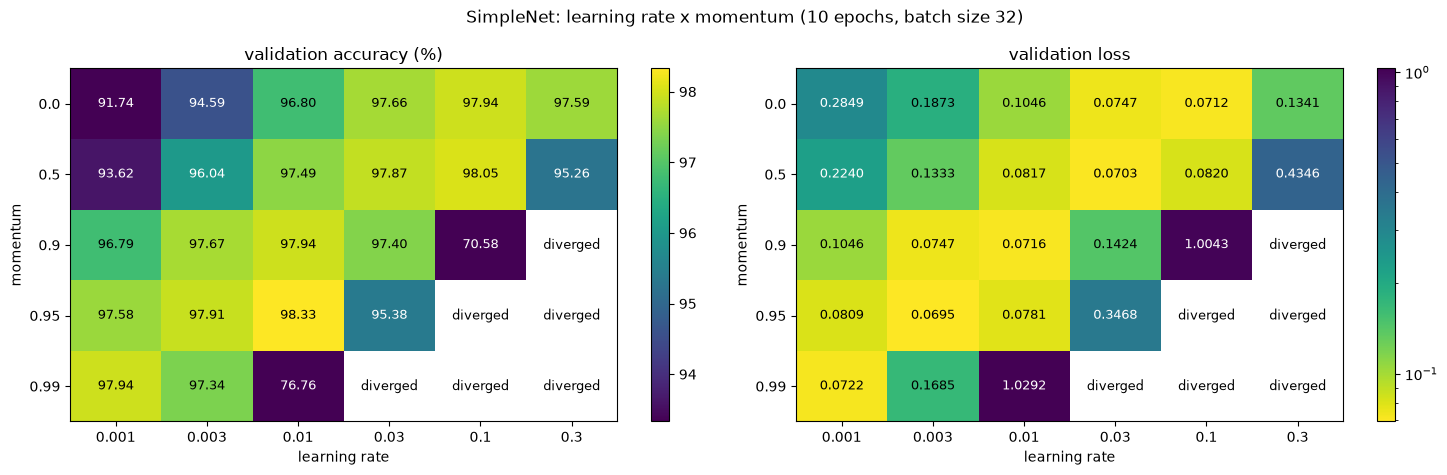

Highest validation accuracy: 98.33% (loss 0.0781) with momentum = 0.95, learning rate = 0.01
Lowest validation loss:      0.0695 (accuracy 97.91%) with momentum = 0.95, learning rate = 0.003


In [13]:
learning_rates = [0.001, 0.003, 0.01, 0.03, 0.1, 0.3]
momentums = [0.0, 0.5, 0.9, 0.95, 0.99]
lr_grid = {}
lr_nets = {}
start = time.time()
for momentum in momentums:
    for lr in learning_rates:
        torch.manual_seed(SEED)
        model = SimpleNet()
        train(model, GPULoader(X_train, Y_train, 32, shuffle=True), epochs=10, lr=lr, momentum=momentum, verbose=False)
        lr_grid[(momentum, lr)] = evaluate(model, val_gpu)
        lr_nets[(momentum, lr)] = model.state_dict()
        loss, acc = lr_grid[(momentum, lr)]
        print(f"momentum {momentum:<5} | lr {lr:<6} -> validation loss {loss:.4f} | validation accuracy {100 * acc:.2f}%")
print(f"Grid search time: {(time.time() - start) / 60:.1f} min")
plot_grid(lr_grid, momentums, learning_rates, "momentum", "learning rate", "SimpleNet: learning rate x momentum (10 epochs, batch size 32)")
best_momentum, best_lr = report_best(lr_grid, ("momentum", "learning rate"))

The simple network was trained for 10 epochs with every combination of 6 learning rates and 5 momentum values.   
  
The heatmap above shows the validation accuracy and loss for each combination of momentum and learning rate, with momentum being displayed on the vertial axis and the learning rate on the horizonal axis.  
  
The highest validation accuracy found was 98.33% (loss 0.0781) achieved wtih:
- learning rate = 0.01 
- momentum = 0.95  

the lowest validation loss is 0.0695 (accuracy 97.91%) achieved wtih:
- learning rate = 0.003 
- momentum = 0.95

### 8.2 Number of layers and neurons

hidden layers 1 | neurons per layer 128  | parameters    101,770 -> validation loss 0.1377 | validation accuracy 97.40%
hidden layers 1 | neurons per layer 256  | parameters    203,530 -> validation loss 0.0962 | validation accuracy 97.94%
hidden layers 1 | neurons per layer 512  | parameters    407,050 -> validation loss 0.0880 | validation accuracy 98.07%
hidden layers 1 | neurons per layer 1024 | parameters    814,090 -> validation loss 0.0830 | validation accuracy 98.03%
hidden layers 1 | neurons per layer 2048 | parameters  1,628,170 -> validation loss 0.0837 | validation accuracy 98.06%
hidden layers 2 | neurons per layer 128  | parameters    118,282 -> validation loss 0.1730 | validation accuracy 96.94%
hidden layers 2 | neurons per layer 256  | parameters    269,322 -> validation loss 0.1296 | validation accuracy 97.38%
hidden layers 2 | neurons per layer 512  | parameters    669,706 -> validation loss 0.1021 | validation accuracy 98.06%
hidden layers 2 | neurons per layer 1024

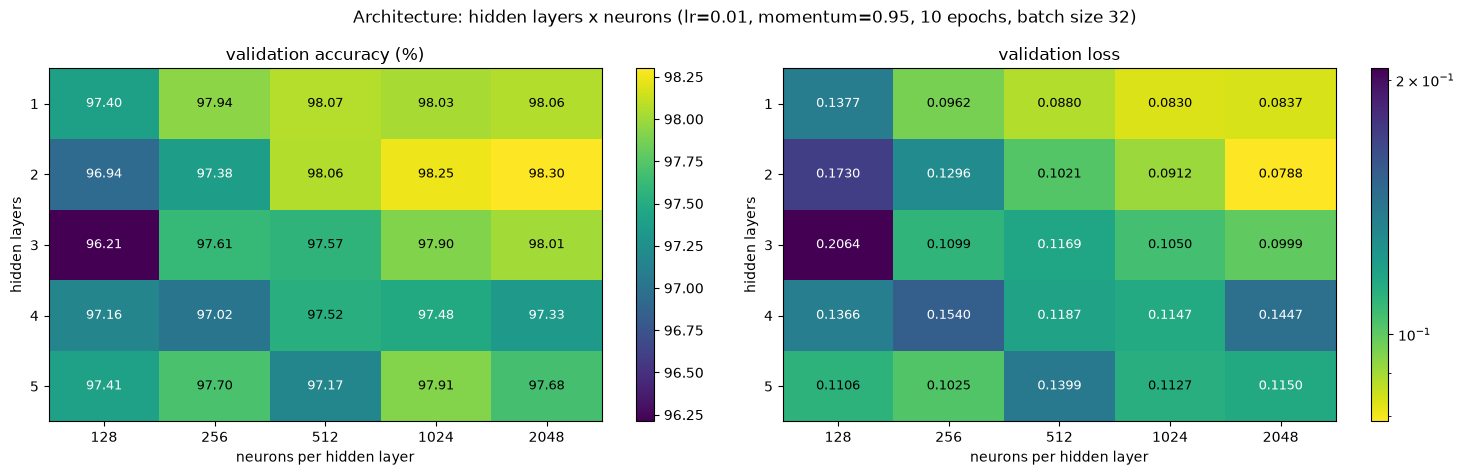

Highest validation accuracy: 98.30% (loss 0.0788) with hidden layers = 2, neurons per layer = 2048
Lowest validation loss:      0.0788 (accuracy 98.30%) with hidden layers = 2, neurons per layer = 2048


In [14]:
depths = [1, 2, 3, 4, 5]
widths = [128, 256, 512, 1024, 2048]
arch_grid = {}
arch_nets = {}
start = time.time()
for depth in depths:
    for width in widths:
        torch.manual_seed(SEED)
        model = MLP([width] * depth)
        train(model, GPULoader(X_train, Y_train, 32, shuffle=True), epochs=10, lr=best_lr, momentum=best_momentum, verbose=0)
        arch_grid[(depth, width)] = evaluate(model, val_gpu)
        arch_nets[(depth, width)] = model.state_dict()
        loss, acc = arch_grid[(depth, width)]
        parameters = sum(p.numel() for p in model.parameters())
        print(f"hidden layers {depth} | neurons per layer {width:<4} | parameters {parameters:>10,} -> validation loss {loss:.4f} | validation accuracy {100 * acc:.2f}%")
print(f"Grid search time: {(time.time() - start) / 60:.1f} min")
plot_grid(arch_grid, depths, widths, "hidden layers", "neurons per hidden layer",
          f"Architecture: hidden layers x neurons (lr={best_lr}, momentum={best_momentum}, 10 epochs, batch size 32)")
best_depth, best_width = report_best(arch_grid, ("hidden layers", "neurons per layer"))

We used the best learning rate and momentum from 8.1 to choose the network size.  

We tested multiple architectures by training each for 10 epochs:
- networks with 1–5 hidden layers
- 128–2048 neurons

You can see the best performing architecture in the rightmost column on the second row with accuracy = 98.30% and validation loss 0.0788
- hidden layers = 2
- neurons per layer = 2048

### 8.3 Final tuned model

MLP(
  (layers): Sequential(
    (0): Linear(in_features=784, out_features=2021, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.04871475937647833, inplace=False)
    (3): Linear(in_features=2021, out_features=2021, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.04871475937647833, inplace=False)
    (6): Linear(in_features=2021, out_features=2021, bias=True)
    (7): ReLU()
    (8): Dropout(p=0.04871475937647833, inplace=False)
    (9): Linear(in_features=2021, out_features=2021, bias=True)
    (10): ReLU()
    (11): Dropout(p=0.04871475937647833, inplace=False)
    (12): Linear(in_features=2021, out_features=10, bias=True)
  )
)
Trainable parameters: 13,866,091
epoch   1/300 | train loss 0.9628 | train accuracy 68.41% | test loss 0.1669 | test accuracy 94.74%
epoch   2/300 | train loss 0.4173 | train accuracy 86.79% | test loss 0.1154 | test accuracy 96.29%
epoch   3/300 | train loss 0.3166 | train accuracy 90.01% | test loss 0.0803 | test accuracy 97.53%
epoch   4/300 | train loss 0

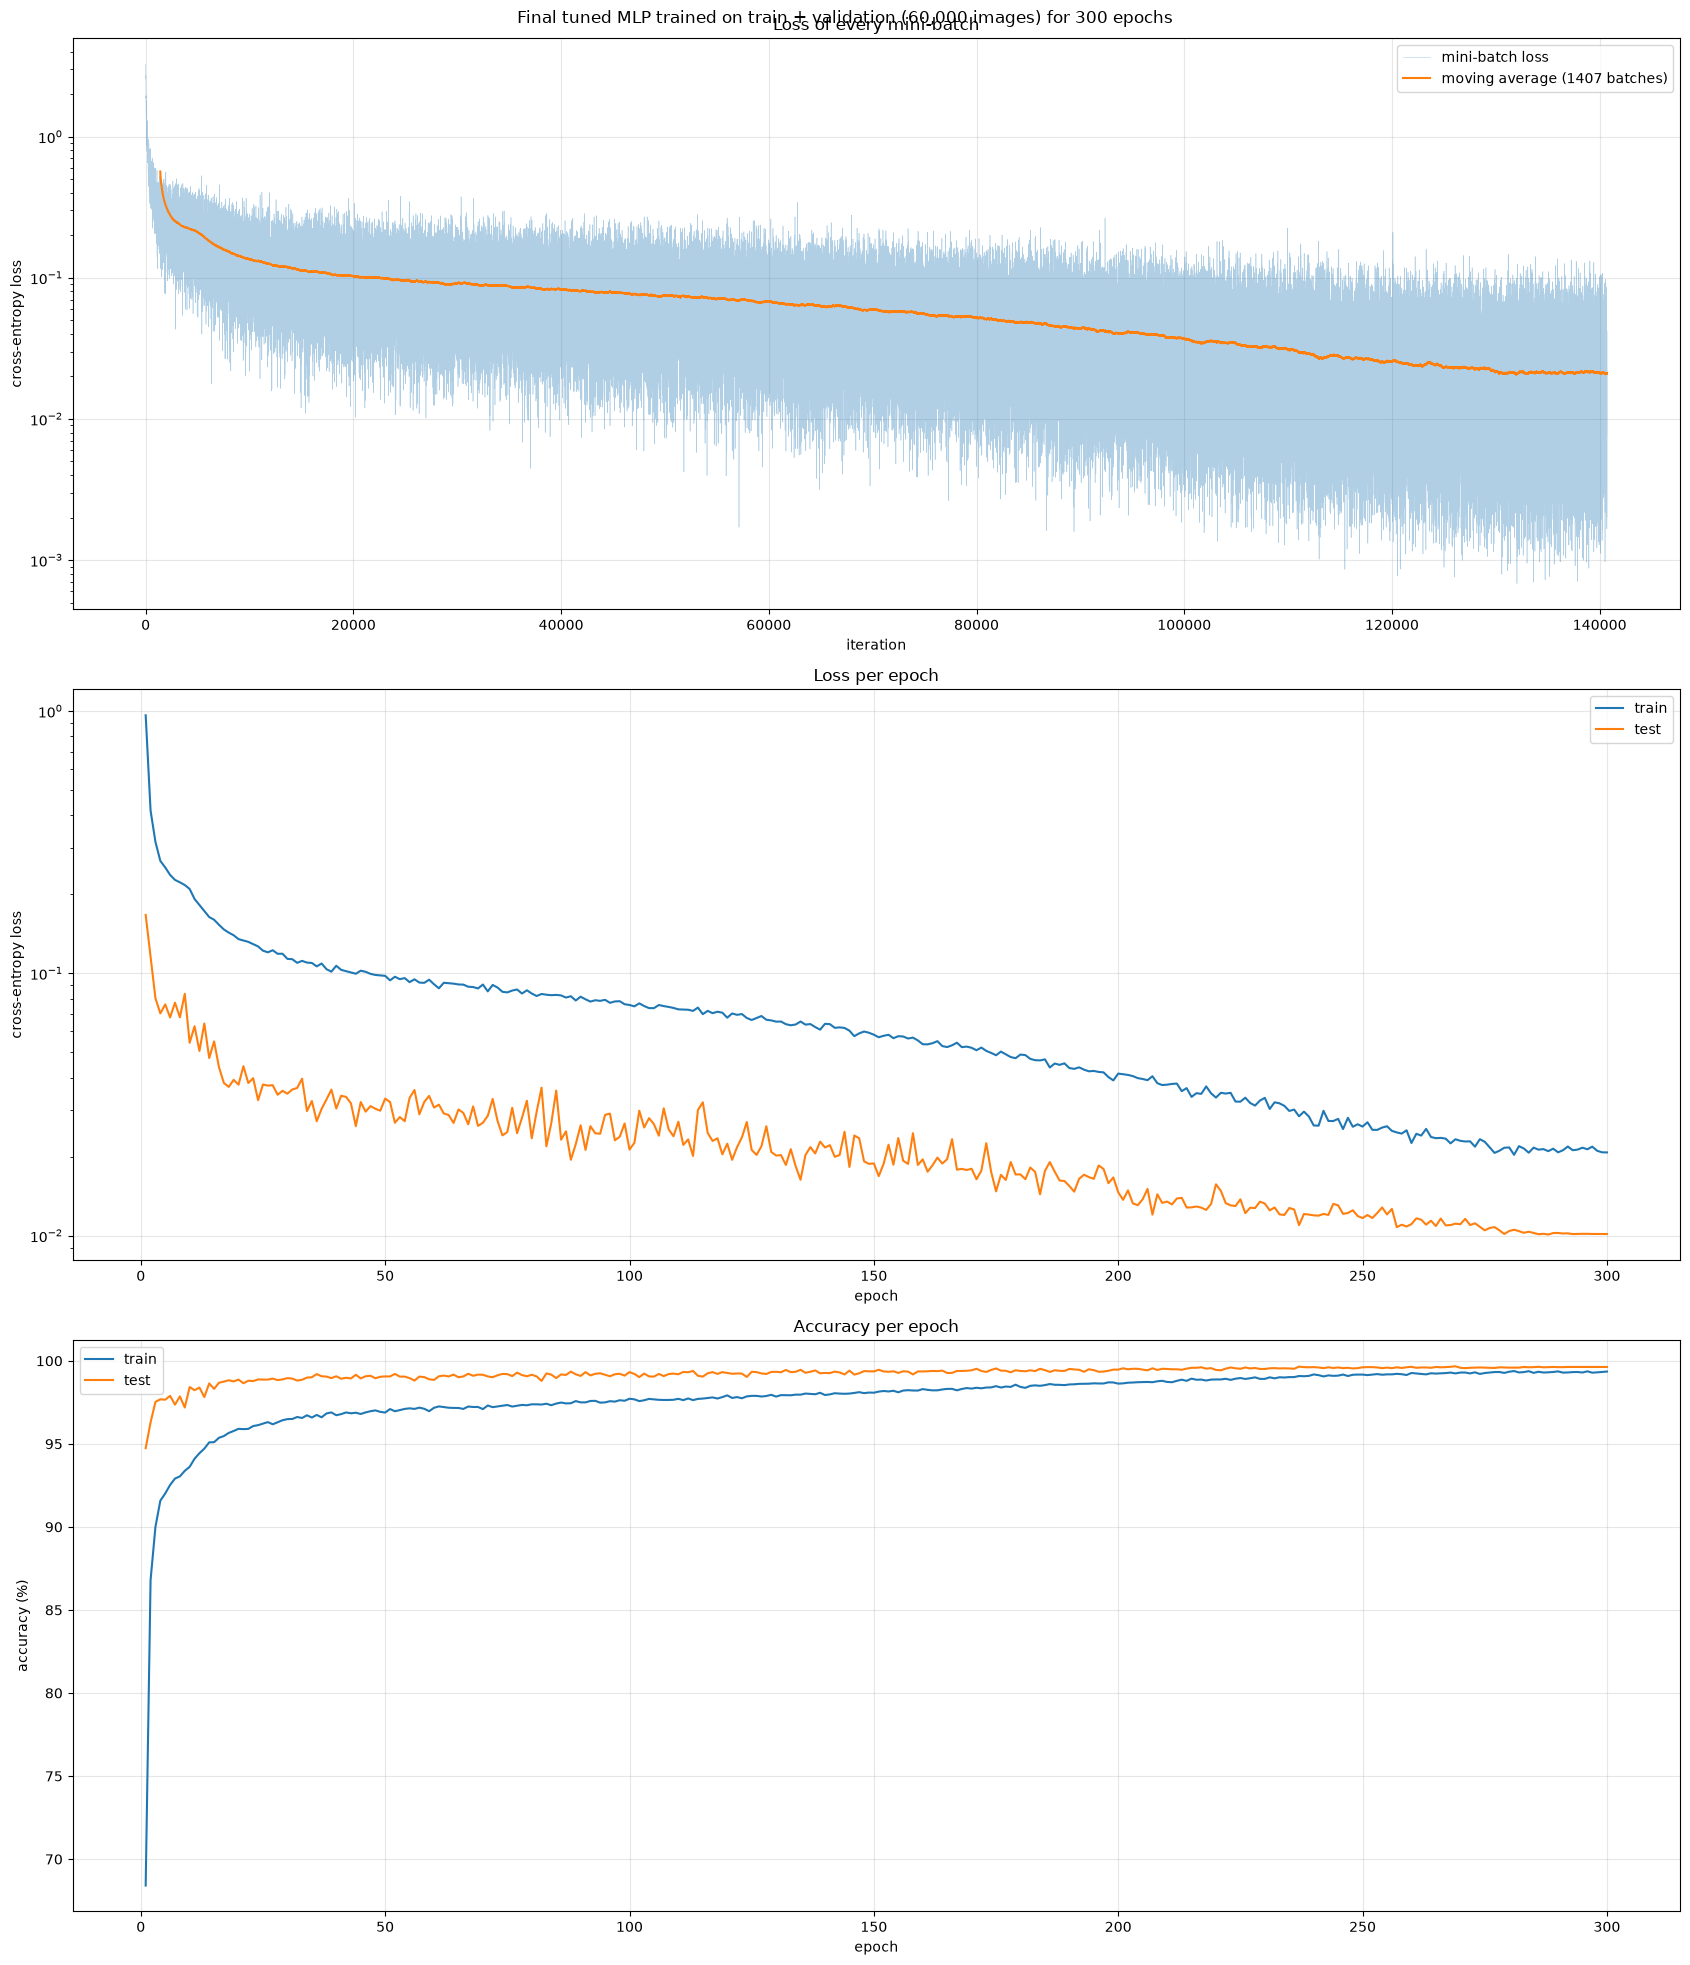

In [15]:
# best configuration from the Bayesian hyperparameter search (validation set) of the full notebook
best = {"layers": 4, "neurons": 2021, "lr": 0.07944420301182344, "momentum": 0.8965033464201944,
        "dropout": 0.04871475937647833, "weight_decay": 8.676777268137569e-05, "batch_size": 128}
augmentation = {"rotate": 12.53398762424148, "scale": 0.1698061790231574, "shear": 15.897545636143303,
                "shift": 0.0785776194284907, "elastic": 28.131149079301103}


torch.manual_seed(SEED)
final_net = MLP([best["neurons"]] * best["layers"], best["dropout"])
print(final_net)
print(f"Trainable parameters: {sum(p.numel() for p in final_net.parameters()):,}")

start = time.time()
final_loader = GPULoader(X_all, Y_all, best["batch_size"], shuffle=True, augmentation=augmentation)
final_losses, final_history = train(final_net, final_loader, epochs=300, lr=best["lr"], momentum=best["momentum"],
                                    weight_decay=best["weight_decay"], nesterov=True, cosine=True,
                                    val_loader=test_gpu, val_name="test")

print(f"Training time: {(time.time() - start) / 60:.1f} min")

final_loss, final_acc = evaluate(final_net, test_gpu)
print(f"\nFinal model on the {len(X_test)} test images:")
print(f"loss {final_loss:.4f}")
print(f"accuracy {100 * final_acc:.2f}%")
print(f"errors {round((1 - final_acc) * len(X_test))} out of {len(X_test)} test images")
plot_training(final_losses, final_history, "Final tuned MLP trained on train + validation (60,000 images) for 300 epochs", val_name="test")

You can see that both the test accuracy and loss out perform the training, this is due to two reasons:
1. Data augmentation was applied to only the training set, this allows the model to become more generalizable and overcome the overfitting issue encoutered earlier in task 6.
2. We added drop out layers to stop the model from overfitting, they are disabled during testing, resulting in lower loss.  

This graph confirms that the model is not overfitting.

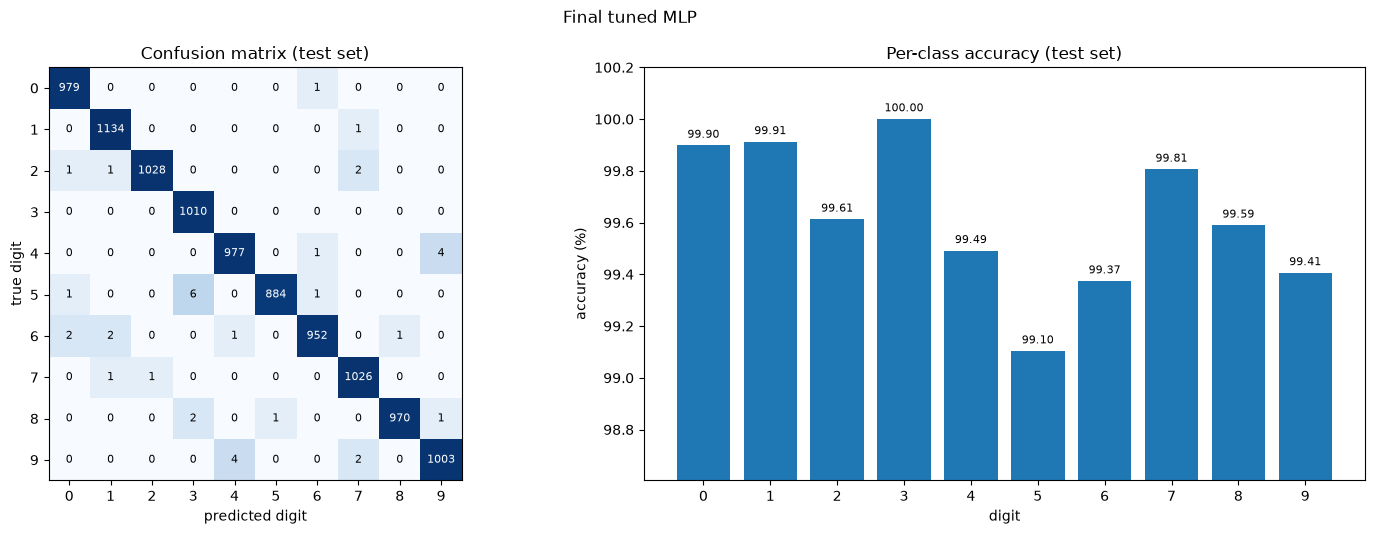

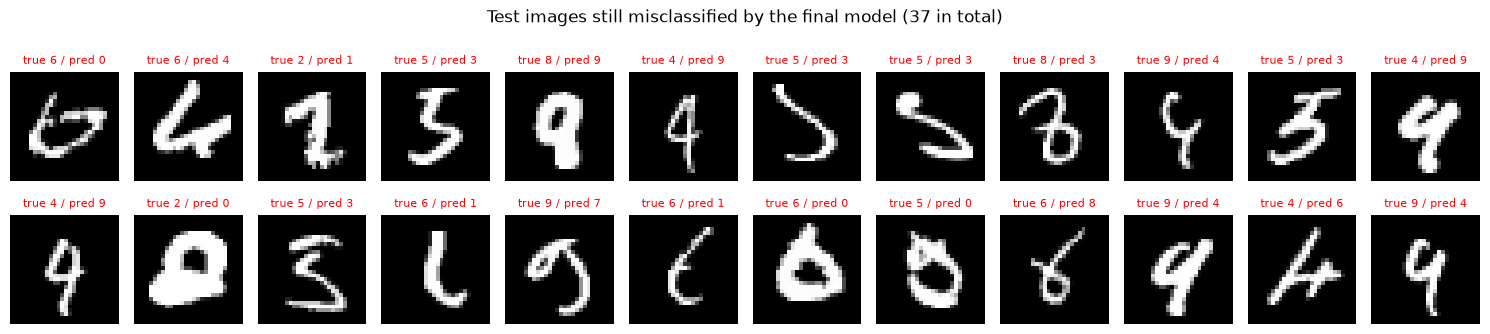

In [16]:
misclassified, final_predictions = plot_confusion(final_net, test_gpu, "Final tuned MLP")
fig, axes = plt.subplots(2, 12, figsize=(15, 3.6))
for i in range(24):
    index = misclassified[i]
    axes.flat[i].imshow(X_test[index].squeeze().cpu(), cmap="gray")
    axes.flat[i].set_title(f"true {Y_test[index].item()} / pred {final_predictions[index]}", fontsize=8, color="red")
    axes.flat[i].axis("off")
fig.suptitle(f"Test images still misclassified by the final model ({len(misclassified)} in total)")
plt.tight_layout()
plt.show()

The final network uses the best configuration found by a Bayesian hyperparameter search (Optuna TPE with Hyperband early stopping, evaluated on the validation set): 
- 4 hidden layers of 2021 neurons, 
- learning rate 0.0794 and momentum 0.8965 (Nesterov SGD), 
- with weight decay 8.7e-5, dropout 0.049, batch size 128, 
- trained for 300 epochs  

The final results were:
- test loss of 0.0101 and
- test accuracy of 99.63% (37 errors out of 10,000)  
  
  
| Model | Test loss | Test accuracy |
|---|---|---|
| SimpleNet baseline (Task 6) | 0.0600 | 98.35% |
| SimpleNet with the best learning rate and momentum (8.1) | 0.0705 | 98.31% |
| Best architecture from the grid, 2 × 2048 neurons (8.2) | 0.0692 | 98.39% |
| Final tuned model, 4 × 2021 neurons (8.3) | **0.0101** | **99.63%** |

## Task #9: Save your source code

In [17]:
torch.save(final_net.state_dict(), "mnist_mlp_final.pt")

reloaded = MLP([best["neurons"]] * best["layers"], best["dropout"]).to(device)
reloaded.load_state_dict(torch.load("mnist_mlp_final.pt"))
loss, acc = evaluate(reloaded, test_gpu)
print(f"Reloaded model from mnist_mlp_final.pt -> test loss {loss:.4f} | test accuracy {100 * acc:.2f}%")

!jupyter nbconvert --to script "Assigment-1 DL - simplified.ipynb"
for file in ["Assigment-1 DL - simplified.ipynb", "Assigment-1 DL - simplified.py", "mnist_mlp_final.pt"]:
    print(f"{file:40s} {os.path.getsize(file) / 2**20:8.2f} MB")

Reloaded model from mnist_mlp_final.pt -> test loss 0.0101 | test accuracy 99.63%
Assigment-1 DL - simplified.ipynb            1.28 MB
Assigment-1 DL - simplified.py               0.03 MB
mnist_mlp_final.pt                          52.90 MB


[NbConvertApp] Converting notebook Assigment-1 DL - simplified.ipynb to script
[NbConvertApp] Writing 28029 bytes to Assigment-1 DL - simplified.py


**Result:** the trained final network is saved to `mnist_mlp_final.pt`; reloading it gives the same test result, which confirms
the file is complete. The notebook is also exported as a Python script (`Assigment-1 DL - simplified.py`). Both files are the source code to upload to
GitHub and link on Blackboard.